# 05 · XGBoost con ventana deslizante: el método del paper del integrante 1 aplicado a Cajamarca

## Objetivo

Probar en la leishmaniosis cutánea de Cajamarca el método del paper elegido por el integrante 1:

> Adams Q. H. et al. (2025). *Evaluating the contribution of weather variables to machine learning forecasts of visceral leishmaniasis in Brazil.* Environ. Res.: Health 3 045012. ([PDF](../papers/paper_integrante%201.pdf), [resumen](../papers/paper_integrante1_resumen.pdf))

El paper pronostica casos mensuales de leishmaniosis visceral en 113 municipios de Brasil con **XGBoost**, un modelo de árboles de decisión que se construyen uno tras otro y cada uno corrige los errores de los anteriores. Lo usa para dos tareas:
1. **Regresión:** cuántos casos habrá dentro de 3, 6 y 12 meses.
2. **Clasificación:** si el municipio pasará a un nivel de riesgo que exige intervención. Brasil define ese nivel como un promedio de al menos 2,4 casos por mes en los últimos 3 años.

Las preguntas de este notebook son tres:
- ¿El método del paper predice mejor que los modelos que el equipo ya tenía?
- ¿El clima mejora las predicciones?
- ¿Los resultados del paper se sostienen con nuestros datos?

## De dónde vienen los datos

El notebook no prepara los datos desde cero. Reutiliza el **pipeline base del equipo**, que está en [`src/`](../src/) y se describe en el [README](../README.md). Ese pipeline ya hace cuatro cosas:
- Limpia los casos notificados al CDC-MINSA (2000–2024).
- Asigna a cada distrito la estación meteorológica de SENAMHI más cercana a sus localidades con casos.
- Revisa la calidad del clima diario y lo resume por mes: lluvia total y temperaturas máxima y mínima.
- Prepara tres versiones del clima: sin rellenar, con el 52 % de los meses faltantes rellenados con el mismo mes de años anteriores, y con solo los huecos cortos rellenados.

Ese pipeline también entrenó los modelos de referencia del equipo: un árbol de decisión y un Random Forest. Aquí se comparan contra XGBoost **en exactamente las mismas filas de prueba**. Ningún archivo de esa carpeta se modifica. El código nuevo está en [`src/p1_adams.py`](../src/p1_adams.py).

## Qué se toma del paper y qué se adapta

**Se replica:**
- XGBoost para regresión y clasificación.
- Ventana deslizante de 24 meses.
- Casos de los 12 meses anteriores y promedio de los últimos 36 meses.
- Clima de los 7 meses anteriores.
- Variables fijas de cada distrito, estandarizadas, y su producto con el clima.
- Optimización bayesiana de hiperparámetros.
- 100 réplicas bootstrap con intervalo del 95 % y cobertura.
- Riesgo por umbral del promedio de 36 meses.
- SHAP.
- Correlación de Spearman entre el desempeño de la regresión y el de la clasificación.

**Se adapta, por estas razones:**
1. **Solo se usa información disponible al momento de predecir.** El paper, por ser un estudio retrospectivo, usa el clima del propio mes que predice. En la práctica ese dato no existiría todavía. Aquí, para predecir a h meses, solo entran datos de hace h meses o más. La forma del paper se muestra una vez, en E2, como comparación.
2. **Un modelo para todos los distritos.** En Cajamarca hay en promedio 0,67 casos por mes por distrito, y el 69 % de los meses tiene cero casos. Con 24 filas un modelo por distrito casi no puede aprender. La versión por distrito igual se mide en E1 y E2b.
3. **Solo las variables que tenemos.** Faltan las del paper sobre humedad, punto de rocío, viento, uso de suelo y actividad humana. Se usan lluvia y temperaturas (SENAMHI), más altitud, latitud, longitud y % de centros poblados urbanos de cada distrito. El índice de El Niño (ONI, de la NOAA) se incluye solo si existe el archivo `data/raw/external/oni.ascii.txt`.
4. **El clima observado termina en 2014–2015.** El efecto del clima solo se puede medir con datos hasta 2014 (experimento E3).

## Experimentos

- **E1:** XGBoost frente a los modelos del equipo (70 distritos, prueba 2019–2024, 5 040 filas idénticas).
- **E2:** pronóstico de casos a 3, 6 y 12 meses con intervalo del 95 %.
- **E2b:** el mismo intervalo con un modelo por distrito, como en el paper.
- **E3:** ¿mejora el clima las predicciones? (46 distritos, prueba 2012–2014).
- **E4:** clasificación de riesgo con umbral de 2,4 y de 1,0 casos por mes.
- **E5:** qué variables pesan más (SHAP) y relación entre regresión y clasificación.

> **Cómo ejecutar:** usar el entorno `.venv` (Python 3.14 con xgboost y optuna). En macOS XGBoost necesita `brew install libomp`. La primera ejecución tarda unos 15 minutos. Los hiperparámetros encontrados se guardan en `results/p1_adams/hiperparametros.json` y se reutilizan; para buscarlos de nuevo, poner `RECALCULAR = True`.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import p1_adams as p1

warnings.filterwarnings("ignore", category=UserWarning)
N_TRIALS = 20        # combinaciones de hiperparámetros probadas por configuración
N_BOOT = 100         # réplicas bootstrap (el paper usa 100)
RECALCULAR = False   # True vuelve a buscar los hiperparámetros
OUT = p1.OUT; PLOTS = ROOT / "results/plots"
PLOTS.mkdir(parents=True, exist_ok=True)

# Estilo de gráficos: fondo claro, texto gris oscuro y colores fijos por papel.
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29d"   # XGBoost, equipo, intervalo, referencia
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titlesize": 11, "legend.frameon": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
T0 = time.time()
print("XGBoost", p1.xgb.__version__, "| resultados en:", OUT.relative_to(ROOT))

XGBoost 3.4.1 | resultados en: results/p1_adams


## 1. Datos

- **Casos:** se cuentan por distrito y mes, de enero de 2000 a diciembre de 2024. Un mes sin notificaciones vale cero.
- **Distritos:** se usan los 70 distritos de Cajamarca con al menos 50 casos en total, los mismos de los modelos del equipo.
- **Variables fijas de cada distrito:** altitud, latitud y longitud de la capital, y % de centros poblados urbanos. Se estandarizan (media 0, desviación 1) para que queden en la misma escala.

In [2]:
U70 = p1.distritos_70()
panel70 = p1.panel_casos(U70)
est70 = p1.estaticas(U70)
ONI = p1.cargar_oni()
print(f"{len(U70)} distritos | {panel70.fecha_mes.min():%Y-%m} a {panel70.fecha_mes.max():%Y-%m} | {len(panel70):,} filas distrito-mes")
print(f"Promedio de casos por distrito y mes: {panel70.casos.mean():.3f} | meses con cero casos: {(panel70.casos == 0).mean():.1%}")
print("Índice El Niño (ONI):", "incluido" if ONI is not None else f"no incluido (falta {p1.ONI_PATH.relative_to(ROOT)})")
est70.describe().loc[["mean", "std", "min", "max"]].rename(index={"mean": "media", "std": "desviación", "min": "mínimo", "max": "máximo"})

70 distritos | 2000-01 a 2024-12 | 21,000 filas distrito-mes
Promedio de casos por distrito y mes: 0.658 | meses con cero casos: 68.8%
Índice El Niño (ONI): no incluido (falta data/raw/external/oni.ascii.txt)


,altitud,latitud,longitud,pct_urbano
media,0.0000,0.0000,0.0000,-0.0000
desviación,1.0000,1.0000,1.0000,1.0000
mínimo,-2.2026,-1.7936,-1.7446,-1.1235
máximo,1.9663,2.1005,2.2407,4.4827


## E1. XGBoost frente a los modelos del equipo

Los modelos del equipo se entrenaron una sola vez con datos hasta 2018 y se evaluaron en 2019–2024: 70 distritos × 72 meses = 5 040 filas. Sus predicciones están guardadas, así que XGBoost se evalúa en **esas mismas filas**. Todas las variantes predicen el mes siguiente (h = 1), igual que los modelos del equipo, y solo usan casos y variables fijas del distrito: en 2019–2024 no hay clima observado.

| Variante | Qué se cambia respecto del Random Forest del equipo |
|---|---|
| **E1a** | Solo el algoritmo: XGBoost con las mismas 7 variables y un solo entrenamiento hasta 2018 |
| **E1b** | El método del paper: sus variables y ventana deslizante de 24 meses, con un modelo para todos los distritos |
| **E1c** | Igual que E1b, pero con un modelo por distrito, como hace el paper |
| **E1d** | Igual que E1b, pero cada ventana aprende de toda la historia disponible y no solo de 24 meses |

Las 7 variables del equipo son los casos de hace 1, 2, 3 y 12 meses, el promedio de los 3 meses anteriores y el mes del año, codificado con seno y coseno para que diciembre quede junto a enero.

Los hiperparámetros se eligen entrenando hasta 2015 y validando en 2016–2018. Después se dejan fijos para la prueba.

In [3]:
# Predicciones guardadas de los modelos del equipo (mismas 5 040 filas).
equipo = pd.read_csv(p1.BASE / "results/comparacion_70_distritos/predicciones.csv",
                     dtype={"ubigeo": str}, parse_dates=["fecha_mes"])
assert len(equipo) == 5040

# E1a: mismo conjunto de variables que el equipo, un solo entrenamiento.
d_eq, f_eq = p1.variables_equipo(panel70)
par_e1a, _ = p1.optimizar_con_cache("E1a", d_eq, f_eq, "y_casos", "casos",
    p1.ventana_fija("2015-12-01", "2016-01-01", "2018-12-01"), n_trials=N_TRIALS, recalcular=RECALCULAR)
pred_e1a = p1.walk_forward(d_eq, f_eq, "y_casos", "casos",
    p1.ventana_fija("2018-12-01", "2019-01-01", "2024-12-01"), params=par_e1a)

# E1b-d: variables del paper, predicción del mes siguiente.
d1, f1 = p1.construir_variables(panel70, h=1, est=est70)
VAL_1, PRUEBA_1 = p1.ventanas("2016-01", "2018-12", 1), p1.ventanas("2019-01", "2024-12", 1)
par_e1b, _ = p1.optimizar_con_cache("E1b", d1, f1, "y_casos", "casos", VAL_1,
                                    n_trials=N_TRIALS, recalcular=RECALCULAR)
pred_e1b = p1.walk_forward(d1, f1, "y_casos", "casos", PRUEBA_1, params=par_e1b)
pred_e1c = p1.walk_forward(d1, f1, "y_casos", "casos", PRUEBA_1, params=par_e1b, por_distrito=True)
pred_e1d = p1.walk_forward(d1, f1, "y_casos", "casos",
                           p1.ventanas("2019-01", "2024-12", 1, meses_train=None), params=par_e1b)
print(f"Variables del paper disponibles ({len(f1)}):", ", ".join(f1))

Variables del paper disponibles (19): casos_lag1, casos_lag2, casos_lag3, casos_lag4, casos_lag5, casos_lag6, casos_lag7, casos_lag8, casos_lag9, casos_lag10, casos_lag11, casos_lag12, media36_lag1, mes_sin, mes_cos, est_altitud, est_latitud, est_longitud, est_pct_urbano


In [4]:
filas_prueba = equipo[["ubigeo", "fecha_mes", "casos"]].copy()
modelos = {"Equipo · árbol de decisión": equipo.arbol_original,
           "Equipo · Random Forest (solo casos)": equipo.solo_casos,
           "Equipo · Random Forest (con clima rellenado al 52 %)": equipo.estacional_52}
for nombre, pr in [("E1a · XGBoost, 7 variables del equipo, un entrenamiento", pred_e1a),
                   ("E1b · XGBoost, método del paper, un modelo para todos", pred_e1b),
                   ("E1c · XGBoost, método del paper, un modelo por distrito", pred_e1c),
                   ("E1d · XGBoost, método del paper con toda la historia", pred_e1d)]:
    m = filas_prueba.merge(pr[["ubigeo", "fecha_mes", "predicho"]], on=["ubigeo", "fecha_mes"], validate="one_to_one")
    assert len(m) == 5040
    modelos[nombre] = m.predicho
g = panel70.groupby("ubigeo").casos
rez = panel70.assign(mes_anterior=g.shift(1), anio_anterior=g.shift(12))
ref = filas_prueba.merge(rez[["ubigeo", "fecha_mes", "mes_anterior", "anio_anterior"]], on=["ubigeo", "fecha_mes"])
modelos.update({"Referencia · repetir el mes anterior": ref.mes_anterior,
                "Referencia · repetir el mismo mes del año anterior": ref.anio_anterior,
                "Referencia · predecir siempre cero": ref.casos * 0})
e1 = pd.DataFrame([dict(modelo=k, **p1.metricas_regresion(filas_prueba.casos, v)) for k, v in modelos.items()])
rf = e1.loc[e1.modelo == "Equipo · Random Forest (solo casos)", "RMSE"].iloc[0]
e1["cambio de RMSE frente al Random Forest del equipo (%)"] = 100 * (e1.RMSE / rf - 1)
e1 = e1.rename(columns={"n": "filas"})
e1.to_csv(OUT / "e1_metricas.csv", index=False)
pd.DataFrame({"ubigeo": filas_prueba.ubigeo, "fecha_mes": filas_prueba.fecha_mes, "casos": filas_prueba.casos,
              **{k: v.to_numpy() for k, v in modelos.items()}}).to_csv(OUT / "e1_predicciones.csv", index=False)
e1

,modelo,RMSE,MAE,filas,cambio de RMSE frente al Random Forest del equipo (%)
0,Equipo · árbol de decisión,0.9070,0.5761,5040,1.7422
1,Equipo · Random Forest (solo casos),0.8915,0.5647,5040,0.0000
2,Equipo · Random Forest (con clima rellenado al...,0.8908,0.5658,5040,-0.0815
3,"E1a · XGBoost, 7 variables del equipo, un entr...",0.8909,0.6030,5040,-0.0700
4,"E1b · XGBoost, método del paper, un modelo par...",0.8932,0.5447,5040,0.1842
5,"E1c · XGBoost, método del paper, un modelo por...",0.9408,0.5279,5040,5.5252
6,"E1d · XGBoost, método del paper con toda la hi...",0.8975,0.6055,5040,0.6699
7,Referencia · repetir el mes anterior,1.1417,0.5369,5040,28.0677
8,Referencia · repetir el mismo mes del año ante...,1.2217,0.6026,5040,37.0416
9,Referencia · predecir siempre cero,1.0537,0.4135,5040,18.1941


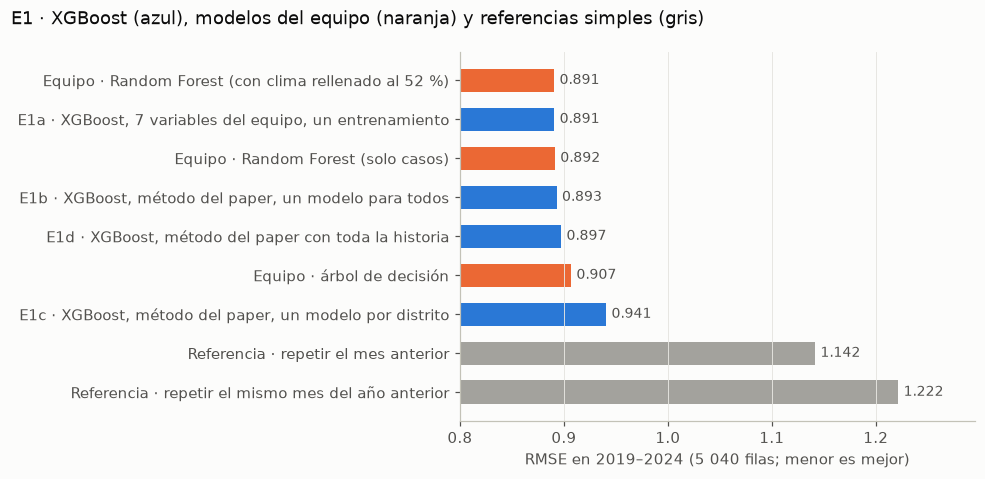

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.4))
e1p = e1[e1.modelo != "Referencia · predecir siempre cero"].sort_values("RMSE", ascending=False)
colores = [AZUL if m.startswith("E1") else (NARANJA if m.startswith("Equipo") else GRIS) for m in e1p.modelo]
ax.barh(e1p.modelo, e1p.RMSE, color=colores, height=0.6)
for y, v in enumerate(e1p.RMSE):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", color=TINTA2, fontsize=9)
ax.set_xlim(0.8, e1p.RMSE.max() * 1.06); ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE en 2019–2024 (5 040 filas; menor es mejor)")
fig.suptitle("E1 · XGBoost (azul), modelos del equipo (naranja) y referencias simples (gris)", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); fig.savefig(PLOTS / "p1_e1_rmse.png"); plt.show()

## E2. Pronóstico de casos a 3, 6 y 12 meses, con intervalo del 95 %

Se sigue el procedimiento del paper:
- **Qué se predice:** el promedio de casos de 3 meses (el mes objetivo y los dos anteriores). Suavizar así reduce el ruido mensual.
- **Cómo se obtiene el intervalo:** en cada ventana se entrenan 100 copias bootstrap. La predicción es la mediana de las copias y el intervalo va del percentil 2,5 al 97,5.
- **Cobertura:** se cuenta en qué porcentaje de meses el valor real cayó dentro del intervalo. El paper obtuvo una mediana de 80,1 % por municipio, con valores entre 50 % y 88,1 %.
- **Referencia simple:** repetir el último promedio de 3 meses que se conocía al momento de predecir.

**Fila "como el paper":** usa casos hasta el mes anterior y el clima del propio mes, aunque el horizonte sea de 3 meses. Ese error es menor por construcción: el promedio que se predice incluye los dos meses anteriores, que también entran como variables. Se muestra solo para ver cuánto cambia el resultado según cómo se arman las variables, no como resultado válido.

In [6]:
E2_CONF = [(3, "operativo"), (6, "operativo"), (12, "operativo"), (3, "paper")]
NOMBRE_MODO = {"operativo": "solo datos disponibles al predecir", "paper": "como el paper (usa datos posteriores)"}
e2_filas, e2_pred, e2_cob, e2_par = [], {}, [], {}
for h, modo in E2_CONF:
    t = time.time()
    d, f = p1.construir_variables(panel70, h=h, modo=modo, est=est70, oni=ONI)
    clave = f"E2_h{h}_{modo}" + ("_oni" if ONI is not None else "")
    par, _ = p1.optimizar_con_cache(clave, d, f, "y_suav", "casos",
        p1.ventanas("2016-01", "2018-12", h, modo=modo), n_trials=N_TRIALS, recalcular=RECALCULAR)
    pr = p1.walk_forward(d, f, "y_suav", "casos", p1.ventanas("2019-01", "2024-12", h, modo=modo),
                         params=par, n_boot=N_BOOT)
    ultimo = d.assign(ultimo_conocido=d.groupby("ubigeo").y_suav.shift(h))[["ubigeo", "fecha_mes", "ultimo_conocido", "casos"]]
    pr = pr.merge(ultimo, on=["ubigeo", "fecha_mes"])
    m = p1.metricas_regresion(pr.observado, pr.predicho, pr.lim_inf, pr.lim_sup)
    cob = p1.por_distrito(pr, "casos").assign(h=h, modo=modo)
    e2_cob.append(cob)
    e2_filas.append({"horizonte (meses)": h, "variables": NOMBRE_MODO[modo], "RMSE": m["RMSE"], "MAE": m["MAE"],
        "RMSE referencia (repetir último valor)": p1.metricas_regresion(pr.observado, pr.ultimo_conocido)["RMSE"],
        "cobertura del intervalo 95 %": m["cobertura_95"], "ancho medio del intervalo": m["ancho_medio"],
        "cobertura mediana por distrito": cob.cobertura_95.median(),
        "cobertura mínima por distrito": cob.cobertura_95.min(), "cobertura máxima por distrito": cob.cobertura_95.max()})
    e2_pred[(h, modo)], e2_par[(h, modo)] = pr, par
    print(f"Horizonte {h:>2} meses, {NOMBRE_MODO[modo]}: listo en {time.time() - t:4.0f} s")
e2 = pd.DataFrame(e2_filas)
e2_cob = pd.concat(e2_cob, ignore_index=True)
e2.to_csv(OUT / "e2_metricas.csv", index=False)
e2_cob.to_csv(OUT / "e2_cobertura_distritos.csv", index=False)
pd.concat([p.assign(h=h, modo=m) for (h, m), p in e2_pred.items()]).to_csv(OUT / "e2_predicciones.csv", index=False)
e2

Horizonte  3 meses, solo datos disponibles al predecir: listo en   98 s


Horizonte  6 meses, solo datos disponibles al predecir: listo en  138 s


Horizonte 12 meses, solo datos disponibles al predecir: listo en  112 s


Horizonte  3 meses, como el paper (usa datos posteriores): listo en  118 s


,horizonte (meses),variables,RMSE,MAE,RMSE referencia (repetir último valor),cobertura del intervalo 95 %,ancho medio del intervalo,cobertura mediana por distrito,cobertura mínima por distrito,cobertura máxima por distrito
0,3,solo datos disponibles al predecir,0.6160,0.3859,0.7573,0.1308,0.2556,0.1111,0.0000,0.3611
1,6,solo datos disponibles al predecir,0.6434,0.3992,0.7915,0.1375,0.3021,0.1111,0.0000,0.3472
2,12,solo datos disponibles al predecir,0.6692,0.4149,0.8289,0.1399,0.2974,0.1250,0.0000,0.3472
3,3,como el paper (usa datos posteriores),0.3264,0.1842,0.7573,0.1107,0.1914,0.0972,0.0000,0.3472


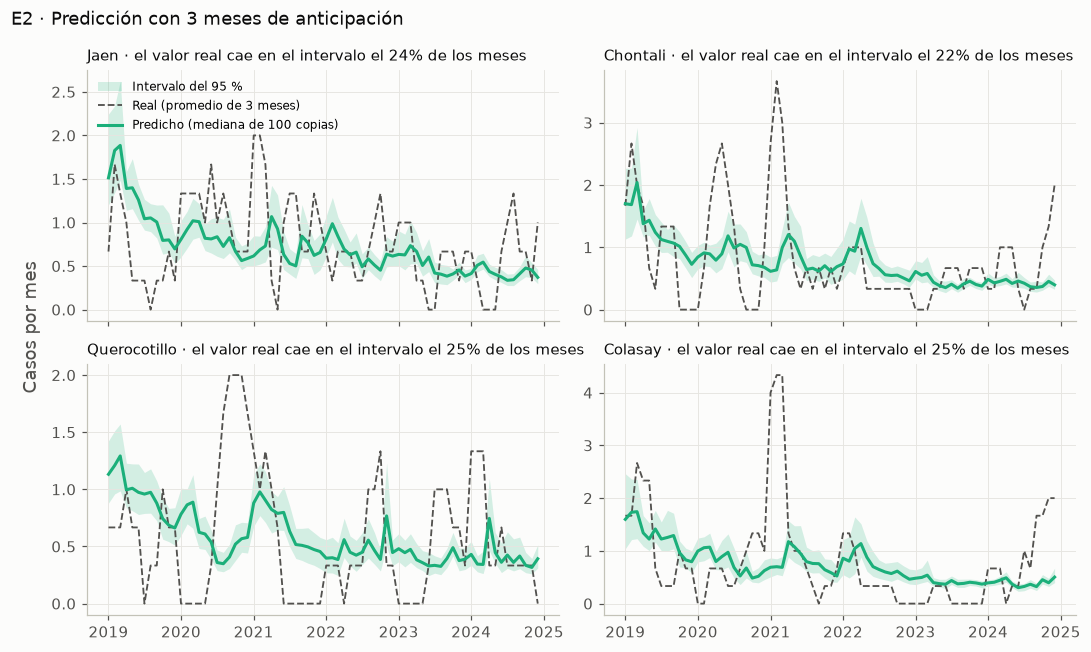

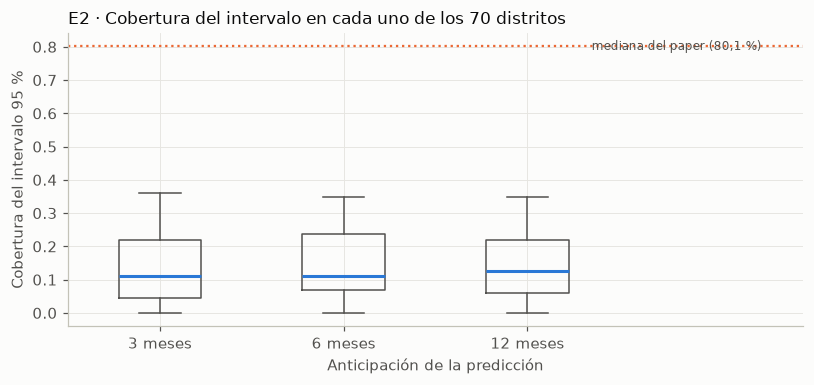

In [7]:
# Valores reales y predichos a 3 meses en los 4 distritos con más casos (equivalente a la figura 1 del paper).
pr = e2_pred[(3, "operativo")]
top4 = panel70.groupby("distrito").casos.sum().nlargest(4).index
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, nombre in zip(axes.flat, top4):
    g = pr[pr.distrito == nombre]
    cob = e2_cob.query("h == 3 and modo == 'operativo' and distrito == @nombre").cobertura_95.iloc[0]
    ax.fill_between(g.fecha_mes, g.lim_inf, g.lim_sup, color=AQUA, alpha=0.18, linewidth=0, label="Intervalo del 95 %")
    ax.plot(g.fecha_mes, g.observado, color=TINTA2, lw=1.2, ls="--", label="Real (promedio de 3 meses)")
    ax.plot(g.fecha_mes, g.predicho, color=AQUA, lw=2, label="Predicho (mediana de 100 copias)")
    ax.set_title(f"{nombre.title()} · el valor real cae en el intervalo el {cob:.0%} de los meses", loc="left", fontsize=10)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supylabel("Casos por mes", color=TINTA2)
fig.suptitle("E2 · Predicción con 3 meses de anticipación", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); fig.savefig(PLOTS / "p1_e2_series_top4.png"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
grupos = [e2_cob.query("modo == 'operativo' and h == @h").cobertura_95 for h in (3, 6, 12)]
ax.boxplot(grupos, tick_labels=["3 meses", "6 meses", "12 meses"], widths=0.45,
           medianprops=dict(color=AZUL, lw=2), boxprops=dict(color=TINTA2), whiskerprops=dict(color=TINTA2),
           capprops=dict(color=TINTA2), flierprops=dict(markeredgecolor=GRIS, markersize=4))
ax.axhline(0.801, color=NARANJA, lw=1.5, ls=":")
ax.text(3.35, 0.801, "mediana del paper (80,1 %)", color=TINTA2, va="center", fontsize=8)
ax.set_ylabel("Cobertura del intervalo 95 %"); ax.set_xlim(0.5, 4.5); ax.set_xlabel("Anticipación de la predicción")
ax.set_title("E2 · Cobertura del intervalo en cada uno de los 70 distritos", loc="left")
fig.tight_layout(); fig.savefig(PLOTS / "p1_e2_cobertura.png"); plt.show()

### E2b. El mismo intervalo con un modelo por distrito, como en el paper

En E2 el modelo aprende de los 70 distritos juntos: 1 680 filas por ventana. Con tantas filas, las 100 copias bootstrap salen casi iguales y el intervalo queda muy estrecho. El paper entrena un modelo por municipio, y cada copia se arma con solo 24 filas, lo que da copias más distintas entre sí y un intervalo más ancho.

Para comprobar si esa diferencia explica la baja cobertura, se repite el horizonte de 3 meses con un modelo por distrito en los 4 distritos del gráfico anterior, con los mismos hiperparámetros.

In [8]:
d3, f3 = p1.construir_variables(panel70, h=3, est=est70, oni=ONI)
sub = d3[d3.distrito.isin(top4)].reset_index(drop=True)
pr_lit = p1.walk_forward(sub, f3, "y_suav", "casos", p1.ventanas("2019-01", "2024-12", 3),
                         params=e2_par[(3, "operativo")], n_boot=N_BOOT, por_distrito=True)
todos = p1.por_distrito(e2_pred[(3, "operativo")][lambda x: x.distrito.isin(top4)], "casos")
uno = p1.por_distrito(pr_lit, "casos")
cols = {"RMSE": "RMSE", "cobertura_95": "cobertura", "ancho_medio": "ancho del intervalo"}
e2b = todos[["distrito", *cols]].rename(columns=cols).merge(uno[["distrito", *cols]].rename(columns=cols),
        on="distrito", suffixes=(" · modelo para todos", " · modelo por distrito"))
e2b.to_csv(OUT / "e2b_por_distrito_top4.csv", index=False)
e2b

,distrito,RMSE · modelo para todos,cobertura · modelo para todos,ancho del intervalo · modelo para todos,RMSE · modelo por distrito,cobertura · modelo por distrito,ancho del intervalo · modelo por distrito
0,QUEROCOTILLO,0.6010,0.2500,0.3033,0.6814,0.3056,0.7678
1,JAEN,0.5434,0.2361,0.3658,0.5651,0.3056,0.6716
2,CHONTALI,0.7535,0.2222,0.4176,0.7697,0.4167,0.8975
3,COLASAY,0.9331,0.2500,0.4138,0.9903,0.4028,1.1307


## E3. ¿Mejora el clima las predicciones?

El clima de las estaciones de SENAMHI llega hasta 2014–2015. Para medir su efecto se usa el periodo 2001–2014, con estos cortes:
- **Distritos:** 46, los que tienen al menos 50 casos hasta 2009. Es la selección que hizo el equipo para este mismo análisis.
- **Validación:** 2010–2011, para elegir hiperparámetros.
- **Prueba:** 2012–2014.

Se comparan tres versiones con las mismas filas de prueba:
- **Solo casos:** sin clima.
- **Clima sin rellenar:** los meses sin dato quedan vacíos. XGBoost sabe trabajar con datos vacíos, así que no hace falta rellenarlos.
- **Clima rellenado al 52 %:** el 52 % de los meses faltantes se completa con el mismo mes de años anteriores.

El clima entra como lluvia total y temperaturas máxima y mínima de los 7 meses anteriores, más su producto con la altitud y con el % urbano del distrito.

Con h = 1 los resultados se comparan con las predicciones guardadas del Random Forest y del árbol de decisión del equipo en este mismo periodo. También se mide h = 3, el horizonte principal del paper.

In [9]:
U46 = p1.distritos_protocolo("historico")
panel46, est46 = p1.panel_casos(U46), p1.estaticas(U46)
versiones = {"solo casos": None, "clima sin imputar": p1.clima_distrito("historico", "sin_imputar"),
             "clima imputación 52 %": p1.clima_distrito("historico", "estacional_52")}
NOMBRE_VERSION = {"solo casos": "solo casos", "clima sin imputar": "con clima sin rellenar",
                  "clima imputación 52 %": "con clima rellenado al 52 %"}
e3_filas, e3_shap = [], {}
for h in (1, 3):
    for version, clima in versiones.items():
        d, f = p1.construir_variables(panel46, h=h, clima=clima, est=est46, oni=ONI)
        clave = f"E3_h{h}_{version}" + ("_oni" if ONI is not None else "")
        par, _ = p1.optimizar_con_cache(clave, d, f, "y_casos", "casos", p1.ventanas("2010-01", "2011-12", h),
                                        n_trials=N_TRIALS, recalcular=RECALCULAR)
        pr, sh = p1.walk_forward(d, f, "y_casos", "casos", p1.ventanas("2012-01", "2014-12", h),
                                 params=par, con_shap=True)
        e3_filas.append({"horizonte (meses)": h, "modelo": f"XGBoost · {NOMBRE_VERSION[version]}", "variables": len(f),
                         **p1.metricas_regresion(pr.observado, pr.predicho)})
        e3_shap[(h, version)] = (sh, f)
# Predicciones guardadas del equipo en el mismo periodo y distritos (predicción del mes siguiente).
guardadas = pd.read_csv(p1.BASE / "results/experimento_clima/predicciones.csv", dtype={"ubigeo": str},
                        parse_dates=["fecha_mes"]).query("protocol == 'historico' and task == 'casos'")
version_equipo = {"solo_casos": "solo casos", "sin_imputar": "con clima sin rellenar", "estacional_52": "con clima rellenado al 52 %"}
nombre_familia = {"random_forest": "Random Forest", "arbol": "árbol de decisión"}
for (fam, var), g in guardadas[guardadas.family.isin(nombre_familia) & guardadas.variant.isin(version_equipo)].groupby(["family", "variant"]):
    assert len(g) == len(pr) == len(U46) * 36
    e3_filas.append({"horizonte (meses)": 1, "modelo": f"Equipo · {nombre_familia[fam]} · {version_equipo[var]}",
                     **p1.metricas_regresion(g.observed, g.predicted)})
e3 = pd.DataFrame(e3_filas).rename(columns={"n": "filas"}).sort_values(["horizonte (meses)", "RMSE"]).reset_index(drop=True)
e3.to_csv(OUT / "e3_metricas.csv", index=False)
e3

,horizonte (meses),modelo,variables,RMSE,MAE,filas
0,1,Equipo · Random Forest · solo casos,NaN,1.0159,0.7185,1656
1,1,Equipo · árbol de decisión · solo casos,NaN,1.0163,0.7217,1656
2,1,Equipo · Random Forest · con clima sin rellenar,NaN,1.0293,0.7322,1656
3,1,Equipo · árbol de decisión · con clima sin rel...,NaN,1.0349,0.7361,1656
4,1,Equipo · Random Forest · con clima rellenado a...,NaN,1.0394,0.7454,1656
5,1,XGBoost · solo casos,19.0000,1.0486,0.6886,1656
6,1,XGBoost · con clima sin rellenar,46.0000,1.0543,0.7084,1656
7,1,Equipo · árbol de decisión · con clima rellena...,NaN,1.0629,0.7677,1656
8,1,XGBoost · con clima rellenado al 52 %,46.0000,1.0820,0.7298,1656
9,3,XGBoost · solo casos,19.0000,1.0709,0.7124,1656


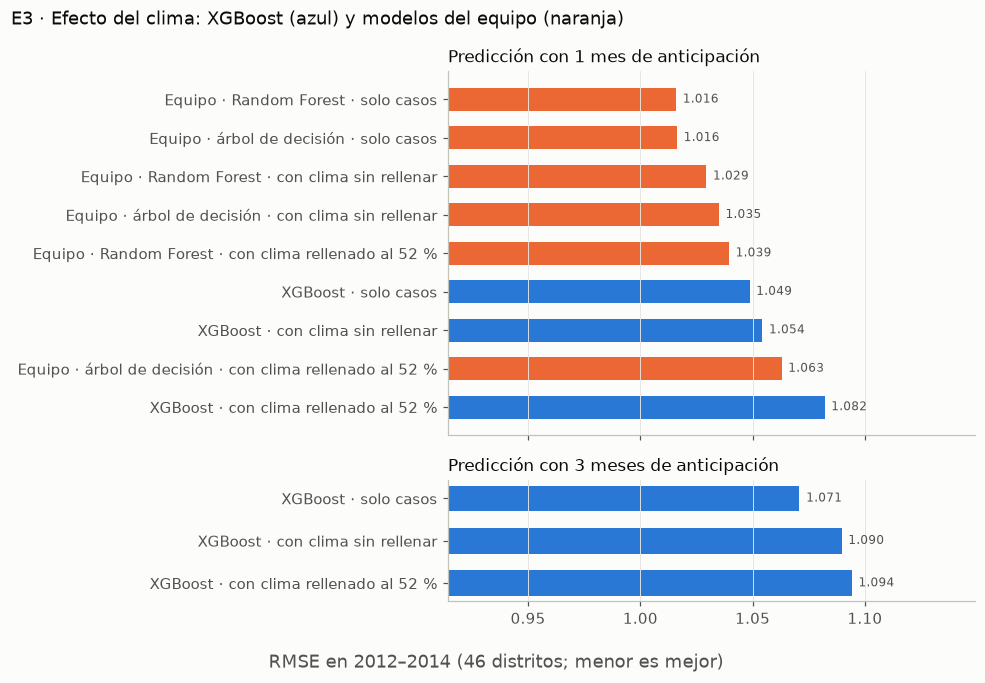

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[9, 3]))
for ax, h in zip(axes, (1, 3)):
    g = e3[e3["horizonte (meses)"] == h].sort_values("RMSE", ascending=False)
    col = [AZUL if m.startswith("XGBoost") else NARANJA for m in g.modelo]
    ax.barh(g.modelo, g.RMSE, color=col, height=0.6)
    for y, v in enumerate(g.RMSE):
        ax.text(v + 0.003, y, f"{v:.3f}", va="center", color=TINTA2, fontsize=8)
    ax.set_title(f"Predicción con {h} mes{'es' if h > 1 else ''} de anticipación", loc="left"); ax.grid(axis="y", visible=False)
    ax.set_xlim(e3.RMSE.min() * 0.9, e3.RMSE.max() * 1.05)
fig.supxlabel("RMSE en 2012–2014 (46 distritos; menor es mejor)", color=TINTA2)
fig.suptitle("E3 · Efecto del clima: XGBoost (azul) y modelos del equipo (naranja)", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); fig.savefig(PLOTS / "p1_e3_clima.png"); plt.show()

## E4. Clasificación de riesgo

Como en el paper, un mes es **de riesgo** si el promedio de casos de los últimos 36 meses (incluido ese mes) alcanza un umbral:
- **Umbral 2,4 casos por mes:** el que usa el Ministerio de Salud de Brasil y el paper. En Cajamarca casi ningún distrito llega a ese nivel.
- **Umbral 1,0 caso por mes:** alternativa para tener suficientes meses de riesgo. No es un umbral oficial; Perú no tiene uno equivalente para la leishmaniosis cutánea.

**Cómo se entrena y se evalúa:**
- El modelo predice el riesgo con 3, 6 y 12 meses de anticipación.
- Es un modelo para los 70 distritos y usa solo datos disponibles al momento de predecir.
- En 2016–2018 se eligen los hiperparámetros (maximizando la average precision) y el puntaje a partir del cual se emite una alerta (el que maximiza F1).
- Esos valores se aplican sin cambios en 2019–2024.

**Referencia simple:** "el distrito mantendrá el nivel de riesgo que tenía cuando se hace la predicción". Como el riesgo se define con un promedio de 36 meses, que cambia muy despacio, esta regla es difícil de superar. El paper no la reporta.

**Resultados por distrito:** igual que en el paper, se calculan solo en los distritos que alguna vez cambiaron de nivel. Esa selección se hace mirando todo el periodo, así que puede hacer que el modelo parezca mejor de lo que sería en la práctica. El propio paper lo advierte.

In [11]:
E4_U, E4_H = (p1.UMBRAL_MOH_BRASIL, 1.0), (3, 6, 12)
e4_filas, e4_dist, e4_pred, e4_shap = [], [], {}, {}
for U in E4_U:
    for h in E4_H:
        t = time.time()
        d, f = p1.construir_variables(panel70, h=h, est=est70, oni=ONI)
        y = p1.etiqueta_riesgo(d, U)
        clave = f"E4_U{U}_h{h}" + ("_oni" if ONI is not None else "")
        VAL = p1.ventanas("2016-01", "2018-12", h)
        par, _ = p1.optimizar_con_cache(clave, d, f, y, "riesgo", VAL, n_trials=N_TRIALS, recalcular=RECALCULAR)
        pv = p1.walk_forward(d, f, y, "riesgo", VAL, params=par).dropna(subset=["observado"])
        corte = p1.umbral_f1(pv.observado, pv.predicho)
        pr, sh = p1.walk_forward(d, f, y, "riesgo", p1.ventanas("2019-01", "2024-12", h), params=par, con_shap=True)
        pr = pr.merge(d[["ubigeo", "fecha_mes", f"media36_lag{h}"]], on=["ubigeo", "fecha_mes"]).dropna(subset=["observado"])
        cambian = p1.distritos_que_alternan(d, U)
        m_mod = p1.metricas_clasificacion(pr.observado, pr.predicho, corte)
        m_ref = p1.metricas_clasificacion(pr.observado, pr[f"media36_lag{h}"].fillna(0), U)
        sin_riesgo = float(pr.groupby("ventana").constante.first().mean())
        e4_filas.append({"umbral": U, "horizonte (meses)": h, "modelo": "XGBoost", "puntaje de alerta": corte,
                         "ventanas sin ningún mes de riesgo para aprender": sin_riesgo, **m_mod})
        e4_filas.append({"umbral": U, "horizonte (meses)": h, "modelo": "Referencia · mantener el nivel actual",
                         "puntaje de alerta": U, **m_ref})
        dist = p1.por_distrito(pr[pr.ubigeo.isin(cambian)], "riesgo", corte).assign(umbral=U, h=h)
        e4_dist.append(dist)
        e4_pred[(U, h)], e4_shap[(U, h)] = pr, (sh, f)
        print(f"Umbral {U}, {h:>2} meses: {len(cambian)} distritos cambiaron de nivel alguna vez; "
              f"{dist.AUC.notna().sum()} tienen meses con y sin riesgo en 2019–2024 | {time.time() - t:3.0f} s")
e4 = pd.DataFrame(e4_filas).rename(columns={"positivos": "meses de riesgo reales", "alertas": "alertas emitidas", "n": "filas"})
e4_dist = pd.concat(e4_dist, ignore_index=True)
e4.to_csv(OUT / "e4_metricas.csv", index=False)
e4_dist.to_csv(OUT / "e4_distritos.csv", index=False)
e4

Umbral 2.4,  3 meses: 15 distritos cambiaron de nivel alguna vez; 3 tienen meses con y sin riesgo en 2019–2024 |   1 s


Umbral 2.4,  6 meses: 15 distritos cambiaron de nivel alguna vez; 3 tienen meses con y sin riesgo en 2019–2024 |   1 s


Umbral 2.4, 12 meses: 15 distritos cambiaron de nivel alguna vez; 3 tienen meses con y sin riesgo en 2019–2024 |   1 s


Umbral 1.0,  3 meses: 46 distritos cambiaron de nivel alguna vez; 17 tienen meses con y sin riesgo en 2019–2024 |   1 s


Umbral 1.0,  6 meses: 46 distritos cambiaron de nivel alguna vez; 17 tienen meses con y sin riesgo en 2019–2024 |   1 s


Umbral 1.0, 12 meses: 46 distritos cambiaron de nivel alguna vez; 17 tienen meses con y sin riesgo en 2019–2024 |   1 s


,umbral,horizonte (meses),modelo,puntaje de alerta,ventanas sin ningún mes de riesgo para aprender,AUC,PR_AUC,precision,recall,F1,meses de riesgo reales,alertas emitidas,filas
0,2.4000,3,XGBoost,0.7510,0.4167,0.8858,0.5045,0.5172,0.7143,0.6000,21,29,5040
1,2.4000,3,Referencia · mantener el nivel actual,2.4000,NaN,0.9994,0.7804,0.7500,0.8571,0.8000,21,24,5040
2,2.4000,6,XGBoost,0.7240,0.4167,0.7719,0.2475,0.3750,0.7143,0.4918,21,40,5040
3,2.4000,6,Referencia · mantener el nivel actual,2.4000,NaN,0.9982,0.5316,0.5556,0.7143,0.6250,21,27,5040
4,2.4000,12,XGBoost,0.9925,0.4167,0.5444,0.0579,0.0667,0.0476,0.0556,21,15,5040
5,2.4000,12,Referencia · mantener el nivel actual,2.4000,NaN,0.9935,0.3036,0.2414,0.3333,0.2800,21,29,5040
6,1.0000,3,XGBoost,0.8461,0.0000,0.9966,0.9702,0.9068,0.9323,0.9194,532,547,5040
7,1.0000,3,Referencia · mantener el nivel actual,1.0000,NaN,0.9977,0.9784,0.9112,0.9455,0.9280,532,552,5040
8,1.0000,6,XGBoost,0.6453,0.0000,0.9903,0.9176,0.7655,0.9511,0.8483,532,661,5040
9,1.0000,6,Referencia · mantener el nivel actual,1.0000,NaN,0.9940,0.9467,0.8456,0.9060,0.8748,532,570,5040


AUC mediana  precisión mediana  recall mediano  \
umbral horizonte (meses)                                                   
1.0000 3                       0.9731             0.8571          0.9565   
       6                       0.9333             0.6500          1.0000   
       12                      0.8164             0.5556          0.8750   
2.4000 3                       0.9714             0.2500          1.0000   
       6                       0.8500             0.1538          1.0000   
       12                      0.6500             0.0000          0.0000   

                          distritos evaluables  distritos con AUC > 0,8  
umbral horizonte (meses)                                                 
1.0000 3                                    17                       15  
       6                                    17                       14  
       12                                   17                        9  
2.4000 3                                     3                        3  
       6                                     3                        2  
       12                                    3                        1

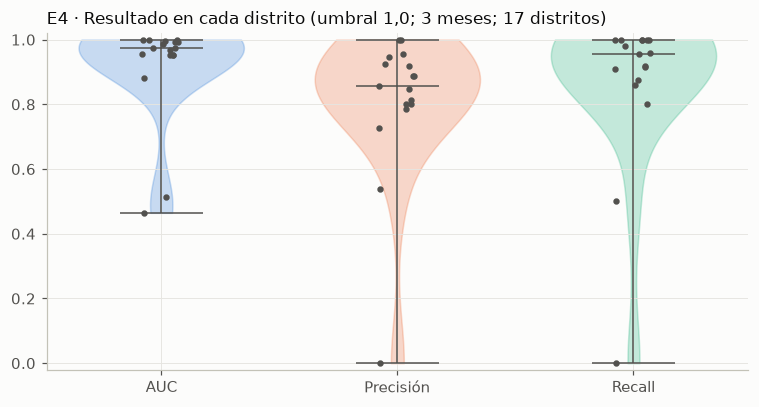

In [12]:
# Resultados por distrito (equivalente a la figura 2 del paper). Con el umbral de 2,4 solo 3 distritos tienen meses con y
# sin riesgo en la prueba; el gráfico usa el umbral de 1,0 y 3 meses de anticipación.
validos = e4_dist.dropna(subset=["AUC"])
resumen = validos.groupby(["umbral", "h"])[["AUC", "precision", "recall"]].median()
resumen.columns = ["AUC mediana", "precisión mediana", "recall mediano"]
resumen["distritos evaluables"] = validos.groupby(["umbral", "h"]).size()
resumen["distritos con AUC > 0,8"] = e4_dist[e4_dist.AUC > 0.8].groupby(["umbral", "h"]).size()
display(resumen.fillna(0).rename_axis(["umbral", "horizonte (meses)"]))

g = e4_dist.query("umbral == 1.0 and h == 3").dropna(subset=["AUC"])
fig, ax = plt.subplots(figsize=(7, 3.8))
datos = [g.AUC, g.precision, g.recall]
partes = ax.violinplot(datos, showmedians=True, widths=0.7)
for b, c in zip(partes["bodies"], (AZUL, NARANJA, AQUA)):
    b.set_facecolor(c); b.set_edgecolor(c); b.set_alpha(0.25)
for k in ("cmedians", "cmins", "cmaxes", "cbars"):
    partes[k].set_color(TINTA2); partes[k].set_linewidth(1)
for i, v in enumerate(datos, start=1):
    ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(v)), v, s=10, color=TINTA2, zorder=3)
ax.set_xticks([1, 2, 3], ["AUC", "Precisión", "Recall"]); ax.set_ylim(-0.02, 1.02)
ax.set_title(f"E4 · Resultado en cada distrito (umbral 1,0; 3 meses; {len(g)} distritos)", loc="left")
fig.tight_layout(); fig.savefig(PLOTS / "p1_e4_distritos.png"); plt.show()

## E5. ¿Qué variables usa el modelo? ¿Coinciden regresión y clasificación?

La importancia de cada variable se mide con SHAP sobre las filas de prueba, en dos modelos:
- **(a) Clasificación de riesgo** (umbral 2,4; 3 meses de anticipación). Es el modelo que interpreta el paper.
- **(b) Regresión con clima sin rellenar** (E3, predicción del mes siguiente). Es el único caso con clima observado.

Las variables se agrupan por tipo (casos, promedio de 36 meses, mes del año, clima, variables fijas del distrito y productos clima × variable fija), como en la figura 3 del paper.

Al final se revisa si los distritos donde la regresión funciona bien son también los de mejor clasificación. Para eso se usa la correlación de Spearman entre la cobertura (E2, 3 meses) y el AUC (E4, umbral 1,0, 3 meses) de cada distrito. El paper obtuvo ρ = 0,25 (p = 0,27), es decir, sin relación clara.

Porcentaje de la importancia total que corresponde a cada tipo de variable:


,(a) clasificación de riesgo,(b) regresión con clima
grupo,,
clima (SENAMHI),0.0000,33.4000
casos de meses anteriores,8.2000,27.3000
promedio de 36 meses,64.4000,15.9000
clima × variable fija,0.0000,12.1000
mes del año,1.3000,6.3000
variable fija del distrito,26.1000,5.0000


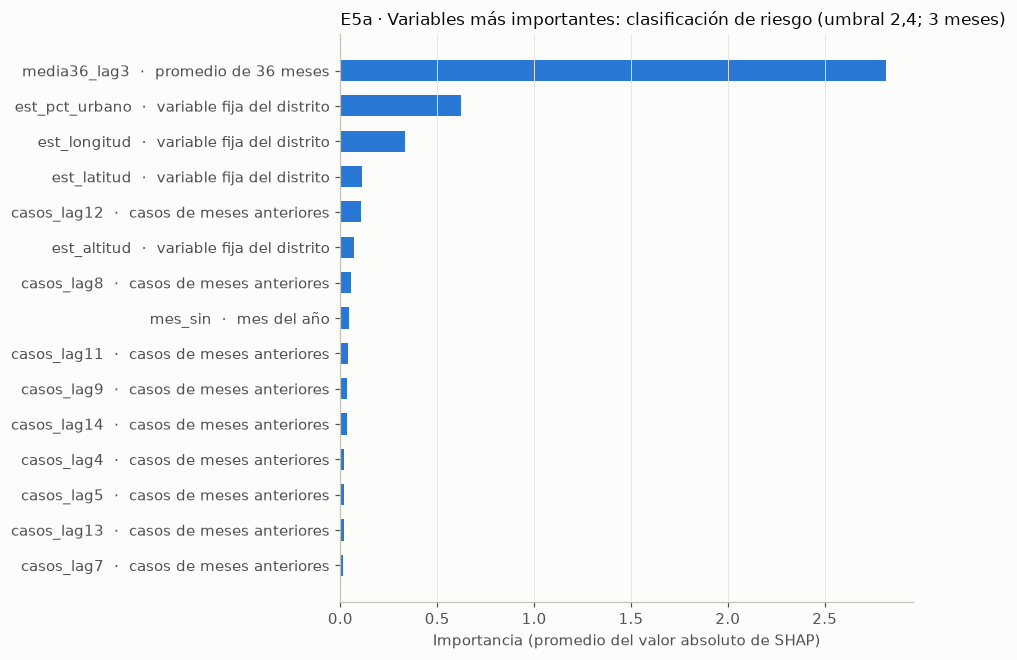

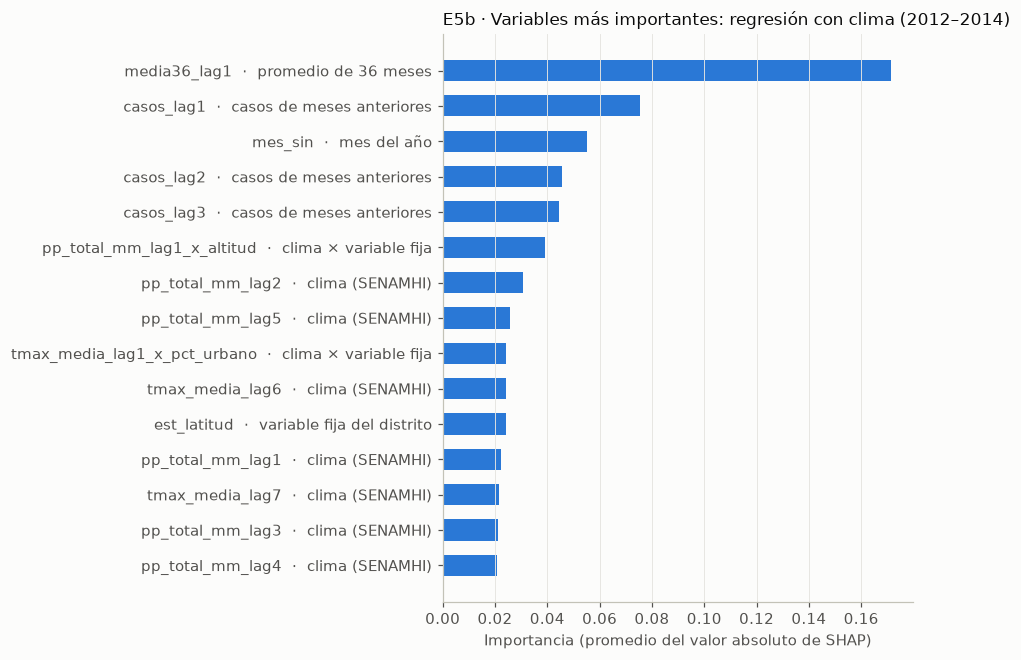

In [13]:
def figura_shap(imp, titulo, archivo, n=15):
    top = imp.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * n + 1.3))
    ax.barh(top.variable + "  ·  " + top.grupo, top.media_abs_shap, color=AZUL, height=0.6)
    ax.grid(axis="y", visible=False); ax.set_xlabel("Importancia (promedio del valor absoluto de SHAP)")
    ax.set_title(titulo, loc="left"); fig.tight_layout(); fig.savefig(PLOTS / f"p1_{archivo}"); plt.show()

sh_a, f_a = e4_shap[(p1.UMBRAL_MOH_BRASIL, 3)]
imp_a = p1.importancia_shap(sh_a, f_a); imp_a.to_csv(OUT / "e5_shap_riesgo_U2.4_h3.csv", index=False)
sh_b, f_b = e3_shap[(1, "clima sin imputar")]
imp_b = p1.importancia_shap(sh_b, f_b); imp_b.to_csv(OUT / "e5_shap_clima_h1.csv", index=False)
grupos = pd.concat([imp_a.groupby("grupo").media_abs_shap.sum().rename("(a) clasificación de riesgo"),
                    imp_b.groupby("grupo").media_abs_shap.sum().rename("(b) regresión con clima")], axis=1)
print("Porcentaje de la importancia total que corresponde a cada tipo de variable:")
display((100 * grupos / grupos.sum()).round(1).sort_values("(b) regresión con clima", ascending=False).fillna(0))
figura_shap(imp_a, "E5a · Variables más importantes: clasificación de riesgo (umbral 2,4; 3 meses)", "e5_shap_riesgo.png")
figura_shap(imp_b, "E5b · Variables más importantes: regresión con clima (2012–2014)", "e5_shap_clima.png")

In [14]:
# Las 5 variables más importantes en los 4 distritos con más casos (equivalente a la figura 4 del paper), modelo (b).
top4_46 = panel46.groupby("distrito").casos.sum().nlargest(4).index
filas = []
for nombre in top4_46:
    s = sh_b[sh_b.distrito == nombre][f_b].abs().mean().nlargest(5)
    filas.append({"distrito": nombre.title(), **{f"puesto {i + 1}": f"{k} ({v:.3f})" for i, (k, v) in enumerate(s.items())}})
display(pd.DataFrame(filas))

# Spearman entre la cobertura de la regresión y el AUC de la clasificación, distrito por distrito.
cob3 = e2_cob.query("h == 3 and modo == 'operativo'")[["ubigeo", "cobertura_95"]]
auc3 = e4_dist.query("umbral == 1.0 and h == 3").dropna(subset=["AUC"])[["ubigeo", "AUC"]]
pares = cob3.merge(auc3, on="ubigeo")
rho, pval = spearmanr(pares.cobertura_95, pares.AUC)
spearman = dict(distritos=len(pares), rho=float(rho), p=float(pval), paper=dict(rho=0.25, p=0.27, municipios=22))
(OUT / "e5_spearman.json").write_text(json.dumps(spearman, indent=2), encoding="utf-8")
print(f"Correlación de Spearman entre cobertura (E2) y AUC (E4): ρ = {rho:.2f}, p = {pval:.3f}, {len(pares)} distritos")

,distrito,puesto 1,puesto 2,puesto 3,puesto 4,puesto 5
0,Jaen,media36_lag1 (0.501),casos_lag1 (0.181),casos_lag3 (0.101),pp_total_mm_lag1_x_altitud (0.093),casos_lag2 (0.083)
1,Chontali,media36_lag1 (0.329),mes_sin (0.068),casos_lag3 (0.058),casos_lag1 (0.056),pp_total_mm_lag2 (0.055)
2,Querocotillo,media36_lag1 (0.509),casos_lag1 (0.116),casos_lag3 (0.081),mes_sin (0.080),casos_lag2 (0.063)
3,Colasay,media36_lag1 (0.462),casos_lag3 (0.077),casos_lag1 (0.074),mes_sin (0.074),casos_lag2 (0.047)


Correlación de Spearman entre cobertura (E2) y AUC (E4): ρ = -0.23, p = 0.376, 17 distritos


In [15]:
# Registro de la ejecución.
meta = dict(semilla=p1.SEED, combinaciones_probadas=N_TRIALS, replicas_bootstrap=N_BOOT, oni_incluido=ONI is not None,
            xgboost=p1.xgb.__version__, pandas=pd.__version__, python=sys.version.split()[0],
            minutos=round((time.time() - T0) / 60, 1))
(OUT / "ejecucion.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False))
print("Archivos generados:", ", ".join(sorted(p.name for p in OUT.glob("*.*"))))

{
  "semilla": 42,
  "combinaciones_probadas": 20,
  "replicas_bootstrap": 100,
  "oni_incluido": false,
  "xgboost": "3.4.1",
  "pandas": "3.1.1",
  "python": "3.14.8",
  "minutos": 14.6
}
Archivos generados: e1_metricas.csv, e1_predicciones.csv, e2_cobertura_distritos.csv, e2_metricas.csv, e2_predicciones.csv, e2b_por_distrito_top4.csv, e3_metricas.csv, e4_distritos.csv, e4_metricas.csv, e5_shap_clima_h1.csv, e5_shap_riesgo_U2.4_h3.csv, e5_spearman.json, ejecucion.json, hiperparametros.json


## Conclusiones

Resultados obtenidos con semilla 42, 20 combinaciones de hiperparámetros por configuración, 100 réplicas bootstrap y sin el índice El Niño.

### 1. XGBoost predice casi igual que el Random Forest del equipo (E1)

- **Mismo conjunto de variables, solo cambia el algoritmo (E1a):** RMSE 0,891 frente a 0,892. El error medio absoluto (MAE) empeora: 0,603 frente a 0,565.
- **Método del paper (E1b):** RMSE 0,893 (0,2 % más alto) y el **menor MAE de todos los modelos entrenados**: 0,545, un 3,5 % menos que el Random Forest. Solo la regla "predecir siempre cero" tiene un MAE menor (0,414), porque el 69 % de los meses tiene cero casos. Esa regla no detecta ningún brote.
- **Un modelo por distrito, como en el paper (E1c):** el RMSE sube 5,5 %. Con tan pocos casos, conviene un modelo para todos los distritos.
- **Toda la historia en vez de 24 meses (E1d):** no mejora.

### 2. A 3, 6 y 12 meses XGBoost supera a la referencia simple, pero su intervalo es demasiado estrecho (E2)

- El error es alrededor de 19 % menor que repetir el último valor conocido. RMSE 0,616, 0,643 y 0,669 frente a 0,757, 0,792 y 0,829.
- El intervalo del 95 % contiene el valor real solo en el 11–13 % de los meses (mediana por distrito). El paper reporta 80 %.
- Con un modelo por distrito (E2b), el intervalo duplica su ancho y la cobertura sube a 31–42 %: la diferencia explica una parte del problema, pero no todo. El resto se debe a que el bootstrap solo mide cuánto varía el modelo, no la variación natural de conteos tan pequeños. **Este intervalo no debe usarse como margen de error de la predicción.**
- La fila "como el paper" tiene un RMSE mucho menor (0,326) porque usa datos que no existirían al momento de predecir. No es comparable.

### 3. El clima no mejora las predicciones (E3)

- Prediciendo el mes siguiente: solo casos RMSE 1,049, con clima sin rellenar 1,054, con clima rellenado al 52 % 1,082. Con 3 meses de anticipación el orden se repite.
- Es lo mismo que encontraron los modelos del equipo, y rellenar el 52 % de los meses empeora el resultado también con XGBoost.
- En ese periodo XGBoost tiene más RMSE que el Random Forest del equipo (1,049 frente a 1,016), pero menos MAE (0,689 frente a 0,719).

### 4. La clasificación de riesgo parece muy buena, pero mantener el nivel actual funciona igual o mejor (E4)

- **Umbral 2,4 (el del paper):**
  - En 2019–2024 hay solo 21 meses de riesgo, en 3 distritos.
  - El 42 % de las ventanas de entrenamiento no tiene ningún mes de riesgo del cual aprender.
  - XGBoost obtiene AUC 0,886, 0,772 y 0,544 a 3, 6 y 12 meses.
- **Umbral 1,0:**
  - AUC 0,997, 0,990 y 0,972.
  - Por distrito, AUC mediana de 0,97, con 15 de 17 distritos por encima de 0,8. El paper tuvo 18 de 22 municipios.
- **La regla "mantener el nivel actual" iguala o supera a XGBoost en todos los casos** (AUC 0,98–0,999 y mejor F1). Como el riesgo se define con un promedio de 36 meses, que cambia muy despacio, un AUC alto en esta tarea dice poco sobre el modelo. El paper no compara contra esta regla, así que sus AUC de 0,84–0,91 deben leerse con esa cautela.

### 5. Qué variables pesan más (E5)

- **Clasificación de riesgo:** el promedio de 36 meses concentra el 64 % de la importancia, las variables fijas del distrito el 26 % (sobre todo el % urbano) y los casos de meses anteriores el 8 %.
- **Regresión con clima:** el clima y sus productos con altitud y % urbano suman el 45 % de la importancia, pero **no reducen el error** (E3). Que el modelo use una variable no significa que mejore la predicción.
- **Correlación de Spearman entre cobertura y AUC por distrito:** ρ = −0,23 (p = 0,38, 17 distritos). No hay relación clara, la misma conclusión del paper.

### Limitaciones

- No se usaron las variables del paper sobre humedad, viento, uso de suelo y actividad humana, ni el índice El Niño.
- Los hiperparámetros se eligen una vez para el modelo de todos los distritos; el paper los elige para cada municipio.
- Los 70 distritos (al menos 50 casos) y los "distritos que cambiaron de nivel" se eligieron mirando todo el periodo 2000–2024, igual que en el paper. Eso puede hacer que los resultados parezcan algo mejores que en la práctica.
- El periodo 2019–2024 ya se había usado para evaluar los modelos del equipo, así que no es una prueba completamente nueva.